<div align="center">
    <img src="neffff.png" width="100%">
</div>

## 📌 Executive Summary
This project delivers a comprehensive **Exploratory Data Analysis (EDA)** on the Netflix Titles dataset (~8,800 records). The goal is to analyze Netflix’s content distribution, evolution over time, dominant genres, target audience demographics, and geographic production hubs to derive strategic content acquisition insights.

### 📋 Table of Contents
1. [Environment Setup & Theming](#1-environment-setup--theming)
2. [Data Loading & Initial Inspection](#2-data-loading--initial-inspection)
3. [Data Cleaning & Imputation](#3-data-cleaning--imputation)
4. [Feature Engineering](#4-feature-engineering)
5. [Exploratory Data Analysis (EDA)](#5-exploratory-data-analysis-eda)
    - 5.1 [Movies vs. TV Shows Ratio](#51-movies-vs-tv-shows-ratio)
    - 5.2 [Target Audience & Content Ratings](#52-target-audience--content-ratings)
    - 5.3 [Content Release Trends Over Time](#53-content-release-trends-over-time)
    - 5.4 [Top Content-Producing Countries](#54-top-content-producing-countries)
    - 5.5 [Dominant Genres & Categories](#55-dominant-genres--categories)
6. [Strategic Takeaways & Conclusion](#6-strategic-takeaways--conclusion)

---

## 1. Environment Setup & Theming
Setting up global visualization parameters with **Netflix Signature Branding** (`#E50914` Red, `#221F1F` Dark Charcoal).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

NETFLIX_RED = "#E50914"
NETFLIX_BLACK = "#221F1F"
NETFLIX_GREY = "#564D4D"

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120

## 2. Data Loading & Initial Inspection
Loading the dataset and checking its dimensions, column data types, and initial rows.

In [2]:
df = pd.read_csv(r"C:\DATA ANALYTICS\DA WITH PYTHON\netflix_titles.csv")

print(f"✅ Dataset Loaded Successfully!")
print(f"📐 Total Rows: {df.shape[0]:,} | Total Columns: {df.shape[1]}")

df.head(3)

✅ Dataset Loaded Successfully!
📐 Total Rows: 8,807 | Total Columns: 12


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [4]:
df.describe(include='all')

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
count,8807,8807,8807,6173,7982,7976,8797,8807.000000,8803,8804,8807,8807
unique,8807,2,8807,4528,7692,748,1767,NaN,17,220,514,8775
top,s1,Movie,Dick Johnson Is Dead,Rajiv Chilaka,David Attenborough,United States,"January 1, 2020",NaN,TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned prope..."
freq,1,6131,1,19,19,2818,109,NaN,3207,1793,362,4
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2014.180198,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.819312,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN,NaN


## 3. Data Cleaning & Imputation
Handling missing values, dropping non-informative unique identifiers, and standardizing formatting.

In [5]:
df=df.drop("show_id",axis=1)

In [6]:
missing_data = df.isnull().sum()
print(missing_data)

type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


In [7]:
df['director'] = df['director'].fillna('Unknown')
df['cast'] = df['cast'].fillna('Unknown')
df['country'] = df['country'].fillna('Unknown')
df.dropna(subset=['date_added'], inplace=True)


In [8]:
df.duplicated().sum()

np.int64(0)

## 4. Feature Engineering
Extracting temporal features (`year_added`, `month_added`) and calculating `content_age` (time gap between official release and Netflix addition).

In [9]:
df['date_added'] = df['date_added'].str.strip()
df['date_added'] = pd.to_datetime(df['date_added'])

df['year_added'] = df['date_added'].dt.year
df['month_added'] = df['date_added'].dt.month_name()

# Calculate Content Age (Years between theatrical release & streaming addition)
df['content_age'] = df['year_added'] - df['release_year']

df[['title', 'release_year', 'year_added', 'content_age']].head(5)

,title,release_year,year_added,content_age
0,Dick Johnson Is Dead,2020,2021,1
1,Blood & Water,2021,2021,0
2,Ganglands,2021,2021,0
3,Jailbirds New Orleans,2021,2021,0
4,Kota Factory,2021,2021,0


## 5. Exploratory Data Analysis (EDA)
In-depth visual analysis of Netflix's catalog distribution and metrics.

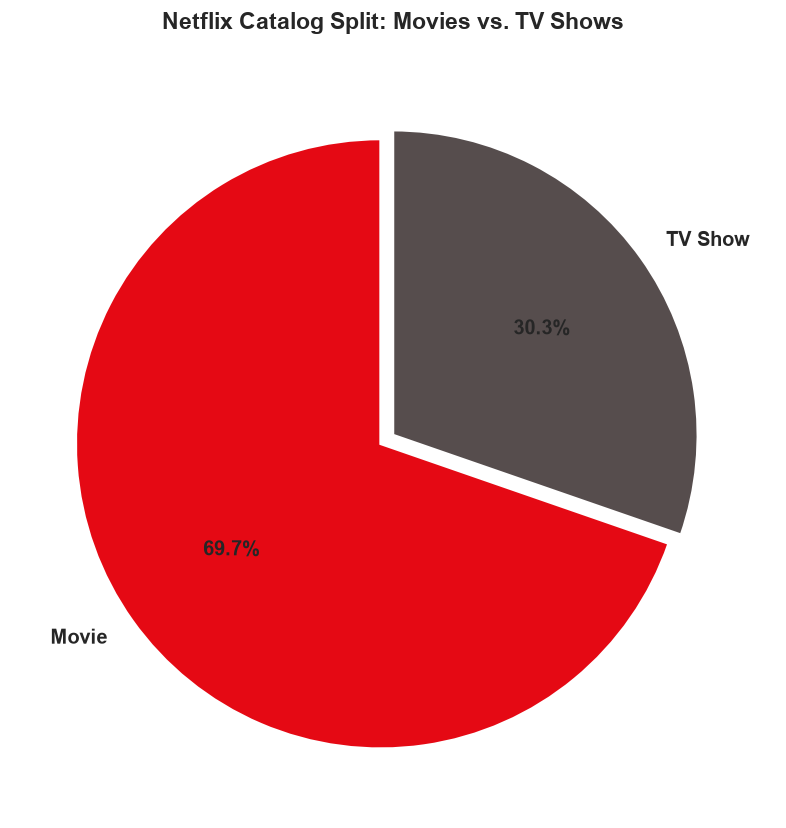

In [10]:
plt.figure(figsize=(7, 7))
type_counts = df['type'].value_counts()

# Explode the 'Movie' slice slightly for aesthetic depth
explode = (0.05, 0) 

plt.pie(type_counts, labels=type_counts.index, autopct='%1.1f%%', 
        colors=[NETFLIX_RED, NETFLIX_GREY], explode=explode, 
        startangle=90, textprops={'fontsize': 12, 'weight': 'bold'},
        shadow=False, wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})

plt.title('Netflix Catalog Split: Movies vs. TV Shows', fontsize=14, weight='bold', pad=15)
plt.tight_layout()
plt.show()


> - **Movies** constitute **~70%** of the platform's library, showing Netflix's historical reliance on film content.
> - **TV Shows** make up the remaining **~30%**, though episodic series generate higher long-term user retention.

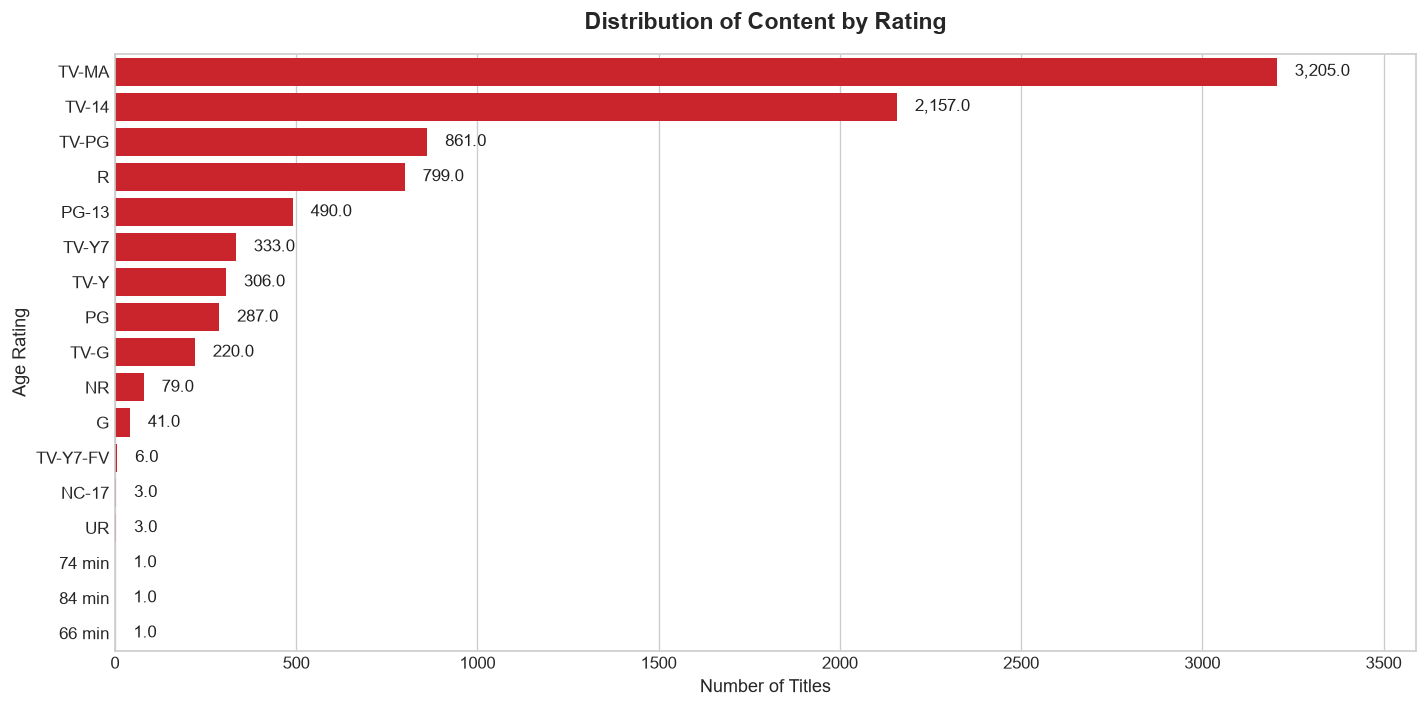

In [11]:
plt.figure(figsize=(12, 6))

rating_order = df['rating'].value_counts().index

ax = sns.countplot(data=df, y='rating', order=rating_order, color=NETFLIX_RED)


for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(f'{width:,}', 
                    (width + 50, p.get_y() + p.get_height() / 2.),
                    ha='left', va='center', fontsize=10, color=NETFLIX_BLACK)

plt.title('Distribution of Content by Rating', fontsize=14, weight='bold', pad=15)
plt.xlabel('Number of Titles', fontsize=11)
plt.ylabel('Age Rating', fontsize=11)
plt.xlim(0, max(df['rating'].value_counts()) * 1.12)
plt.tight_layout()
plt.show()

> - **TV-MA (Mature Audience)** and **TV-14 (Parents Strongly Cautioned)** dominate the platform.
> - Over **60%** of the total catalog is curated for adult and young adult demographics, highlighting a content strategy focused on mature audiences.

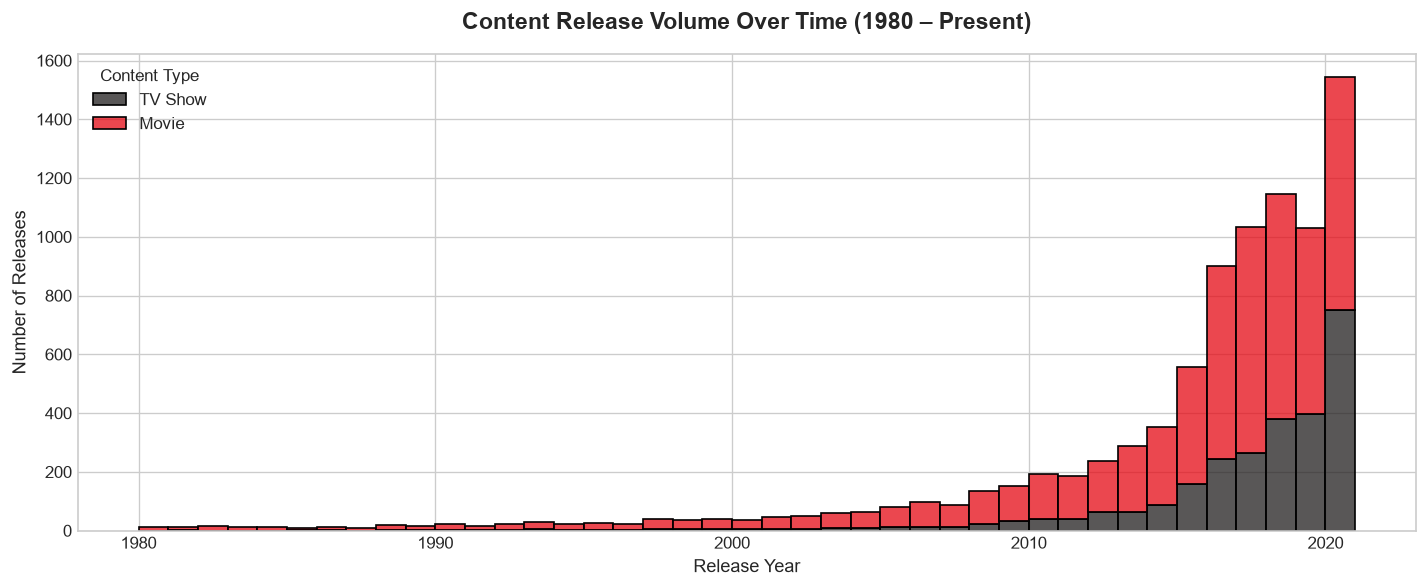

In [12]:
plt.figure(figsize=(12, 5))

df_recent = df[df['release_year'] >= 1980]

sns.histplot(data=df_recent, x='release_year', hue='type', multiple='stack', 
             palette=[NETFLIX_RED, NETFLIX_BLACK], bins=41, kde=False)

plt.title('Content Release Volume Over Time (1980 – Present)', fontsize=14, weight='bold', pad=15)
plt.xlabel('Release Year', fontsize=11)
plt.ylabel('Number of Releases', fontsize=11)
plt.legend(title='Content Type', labels=['TV Show', 'Movie'])
plt.tight_layout()
plt.show()

>
> - Exponential growth occurred between **2015 and 2020**, coinciding with Netflix's massive expansion into **Original Productions**.
> - TV Show additions surged significantly post-2016 compared to older legacy films.

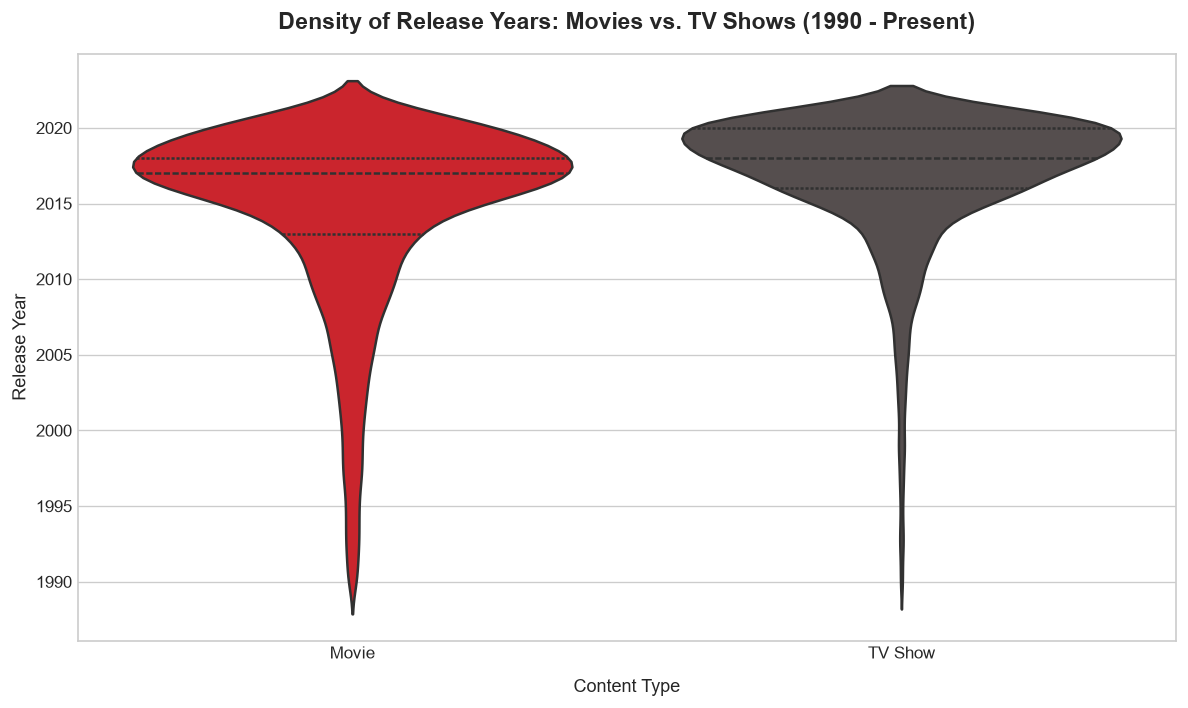

In [13]:
plt.figure(figsize=(10, 6))

# Filter for content post-1990 to avoid extreme long tails distorting the plot scale
df_density = df[df['release_year'] >= 1990]

sns.violinplot(data=df_density, x='type', y='release_year',hue='type', 
               palette=[NETFLIX_RED, NETFLIX_GREY], 
               inner="quartile", linewidth=1.5,legend=False)

plt.title('Density of Release Years: Movies vs. TV Shows (1990 - Present)', fontsize=14, weight='bold', pad=15)
plt.xlabel('Content Type', fontsize=11, labelpad=10)
plt.ylabel('Release Year', fontsize=11)
plt.tight_layout()
plt.show()

> - The **TV Show** distribution is extremely top-heavy (wider at the top), indicating that almost all episodic content on the platform was produced recently (post-2015).
> - **Movies** exhibit a longer "tail" stretching downwards, revealing that Netflix retains a much larger back-catalog of older films compared to classic television series.

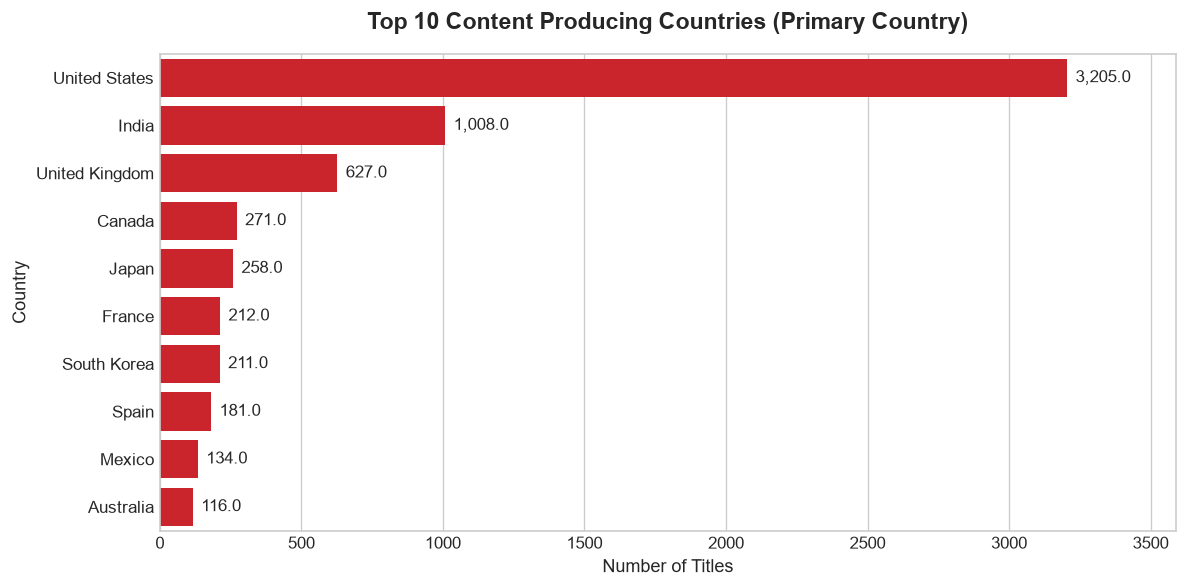

In [14]:
plt.figure(figsize=(10, 5))

primary_country = df['country'].str.split(',').str[0].str.strip()
top_countries = primary_country[primary_country != 'Unknown'].value_counts().head(10)

ax = sns.barplot(x=top_countries.values, y=top_countries.index, color=NETFLIX_RED)

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'{width:,}', 
                (width + 30, p.get_y() + p.get_height() / 2.),
                ha='left', va='center', fontsize=10)

plt.title('Top 10 Content Producing Countries (Primary Country)', fontsize=14, weight='bold', pad=15)
plt.xlabel('Number of Titles', fontsize=11)
plt.ylabel('Country', fontsize=11)
plt.xlim(0, max(top_countries.values) * 1.12)
plt.tight_layout()
plt.show()

> - The **United States** leads content production by a significant margin, followed by **India** and the **United Kingdom**.
> - India’s high ranking emphasizes Netflix's strategic push into Asian regional markets.

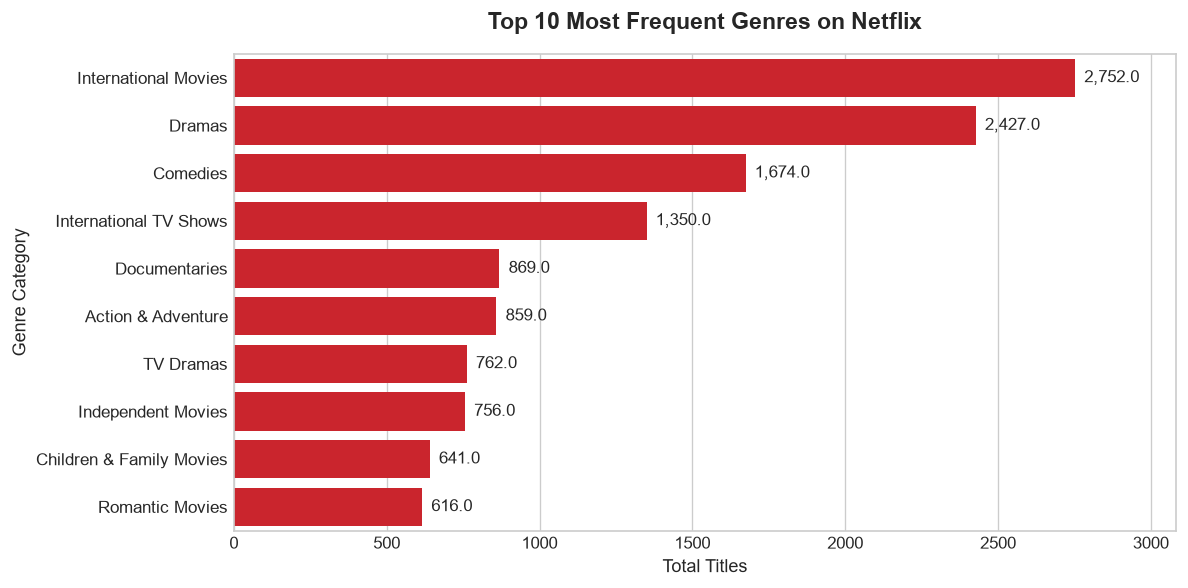

In [15]:
plt.figure(figsize=(10, 5))

genres = df['listed_in'].str.split(',').explode().str.strip().value_counts().head(10)

ax = sns.barplot(x=genres.values, y=genres.index, color=NETFLIX_RED)

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'{width:,}', 
                (width + 30, p.get_y() + p.get_height() / 2.),
                ha='left', va='center', fontsize=10)

plt.title('Top 10 Most Frequent Genres on Netflix', fontsize=14, weight='bold', pad=15)
plt.xlabel('Total Titles', fontsize=11)
plt.ylabel('Genre Category', fontsize=11)
plt.xlim(0, max(genres.values) * 1.12)
plt.tight_layout()
plt.show()

## 6. Strategic Takeaways & Conclusion

### Key Business Findings
1. **Catalog Bias:** Movies dominate Netflix's historical library (~70%), but TV Shows drive recurring engagement and subscriber retention.
2. **Audience Focus:** Content curation heavily favors mature audiences (`TV-MA` and `TV-14`), making up the core demographic.
3. **Regional Markets:** Outside the US, **India** and the **UK** represent the primary content hubs, reflecting targeted global expansion strategies.
4. **Dominant Genres:** *International Movies*, *Dramas*, and *Comedies* form the backbone of the streaming library.

